# E6 — DDR

A class-dependent margin and adjacent-grade penalties investigate whether more explicit boundary supervision changes grade 1 errors.

[Notebook index](../README.md) · [Experiment audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md)

## Protocol and reproducibility

[Runner](../../novelty_integrated/e6/runner.py) · [Protocol and environment](../../novelty_integrated/e6/README.md) · [objective.py](../../novelty_integrated/e6/objective.py) · [decoded_cache.py](../../novelty_integrated/e6/decoded_cache.py) · [config.py](../../novelty_integrated/e6/config.py)

Frozen seed 42 manifest, SHA group isolation, grade order 0–4. Validation uses deterministic transforms and original support. The notebook creates no split.

## Model, inputs and environment

Official Hugging Face ConvNeXt-Tiny V1, pooled width 768. A categorical head emits five logits and an ordered-threshold ordinal head contributes auxiliary supervision. Recorded parameter counts are backbone_total=27,820,128, backbone_trainable=27,820,128, head_total=4,618, total_trainable=27,824,746.

EXIF transpose and RGB, then the pinned official processor at 224 px for resize/crop, rescale and normalization. B1 train-only augmentation is keyed by seed, epoch and image ID. It applies horizontal flip (p=0.50), field-of-view guarded rotation (p=0.50, ±7°), brightness (p=0.30, factor 0.90–1.10), and contrast (p=0.30, factor 0.90–1.10), in that order.

The evidence view requires Python, Jupyter and IPython. Optional source workflows rely on the run-specific PyTorch, Transformers, Pillow and NumPy environment, a verified local snapshot, and external datasets/manifests. The CLI and protocol links describe hardware, caching and environment details.

### Read committed evidence

The setup uses the dataset-specific result and performs no training or inference.

In [ ]:
from pathlib import Path
import hashlib
import json
import os
import sys

from IPython.display import JSON, display

configured_root = os.environ.get("DR_RESEARCH_ROOT")
start = Path(configured_root).expanduser().resolve() if configured_root else Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "notebooks/experiment_workflow.py").is_file() and (p / "novelty_integrated").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DR_RESEARCH_ROOT to the reviewed repository checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

METHOD, DATASET = 'E6', 'DDR'
EVIDENCE = 'results/DDR/e6_ldam_ordinal_adjacent/validation_evidence.json'
blob = json.loads((ROOT / EVIDENCE).read_text(encoding='utf-8'))
RUNS = [blob]
CONFIG = RUNS[0]['configuration'] if RUNS else {}
CHECKPOINT_SHA256 = '7e4bf74ced0daec7f078e7e441551ce40c96c2816eff990d3aafa860f7113df5'
print(f'{METHOD} {DATASET}: {len(RUNS)} published run(s) in this notebook.')

### Optional manifest and checkpoint byte checks

Set `DR_ARTIFACT_ROOT` and optionally `DR_CHECKPOINT` before enabling this read-only gate.

In [ ]:
VERIFY_LOCAL_PROVENANCE = False
if VERIFY_LOCAL_PROVENANCE:
    artifact = os.environ.get("DR_ARTIFACT_ROOT")
    checkpoint = os.environ.get("DR_CHECKPOINT")
    expected = CONFIG.get("manifest", {}).get("manifest_sha256")
    if not artifact or not expected:
        raise ValueError("Set DR_ARTIFACT_ROOT and use a notebook with a verified frozen manifest.")
    manifest = Path(artifact) / "cad_vit_runs" / "manifests" / f"{DATASET}_seed42.csv"
    with manifest.open("rb") as stream:
        if hashlib.file_digest(stream, "sha256").hexdigest() != expected:
            raise ValueError("Frozen manifest hash differs.")
    print("Frozen manifest SHA-256 matches.")
    if checkpoint:
        run_id = os.environ.get("DR_RECORDED_RUN_ID")
        receipts = {r.get("id", r.get("experiment")):
                    r.get("source_sha256", {}).get("best.pt") or
                    r.get("checkpoint_sidecars", {}).get("best.pt", {}).get("sha256") for r in RUNS}
        expected_checkpoint = receipts.get(run_id) if run_id else CHECKPOINT_SHA256
        if len(RUNS) > 1 and not run_id:
            raise ValueError("Set DR_RECORDED_RUN_ID to the relevant B4-Q or B4-R evidence ID.")
        if not expected_checkpoint:
            raise ValueError("No repository-verified checkpoint SHA-256 exists for this run.")
        with Path(checkpoint).open("rb") as stream:
            if hashlib.file_digest(stream, "sha256").hexdigest() != expected_checkpoint:
                raise ValueError("Checkpoint hash differs.")
        print("Checkpoint SHA-256 matches without deserializing weights.")

## E6 recorded configuration and history

[Authoritative aggregate JSON](../../results/DDR/e6_ldam_ordinal_adjacent/validation_evidence.json).

| Recorded field | Value |
| --- | --- |
| model_kind | convnext_tiny |
| seed | 42 |
| epochs | 20 |
| micro_batch | 32 |
| accumulation | 1 |
| effective_batch | 32 |
| precision | bf16 |
| device_type | cuda |
| optimizer | AdamW |
| backbone_lr | 1e-05 |
| head_lr | 0.001 |
| weight_decay | 0.01 |
| max_grad_norm | 1 |
| checkpoint_selection | max validation macro-F1; tie lower validation CE; tie earliest epoch |
| source_git_head | b3dd3ca01936f7d173cb646721271703b4e0308d |
| torch | 2.7.1+cu126 |
| transformers | 4.57.3 |
| pillow | 11.1.0 |
| numpy | 2.5.5 |
| manifest_sha256 | 7bc3e3916e012bc46fcd9cd69aa469e0daf3229e1273f1d8ecb6054899bf6eb1 |
| train / validation counts | {'train': 10018, 'val': 1252} |
| model revision | 6166b7613034066690a621d8bf25ffdf181a34f0 |
| model weights SHA-256 | 1fe15b2eba9e355de14c4e244e6365bf61ffef84da7d3442c0afbb2d8564f477 |
| processor config SHA-256 | fd575b890da5a949493e1d1e7a70bfcb9e4b99fe444004d2dbfa253add254741 |

```json
{
  "b1_augmentation": {
    "implementation_sha256": "cd7cedcbadda52aff69ef9096f24803703d1ec7b1b90dde19d5bdbc41c8c8ea3",
    "pillow_version": "11.1.0",
    "protocol": {
      "brightness_factor": [
        0.9,
        1.1
      ],
      "brightness_probability": 0.3,
      "contrast_factor": [
        0.9,
        1.1
      ],
      "contrast_probability": 0.3,
      "fov_proxy_threshold_max_channel": 8,
      "horizontal_flip_probability": 0.5,
      "minimum_fov_proxy_retention": 0.99,
      "name": "B1-retinal-conservative-v1",
      "order": [
        "horizontal_flip",
        "rotation",
        "brightness",
        "contrast"
      ],
      "rotation_attempts": 8,
      "rotation_degrees": [
        -7.0,
        7.0
      ],
      "rotation_fill": [
        0,
        0,
        0
      ],
      "rotation_probability": 0.5,
      "rotation_resample": "BICUBIC"
    }
  },
  "objective": {
    "adjacent_coefficient": 0.1,
    "adjacent_pairs": [
      [
        0,
        1
      ],
      [
        1,
        2
      ]
    ],
    "categorical": "LDAM true-class margin scaled by 30",
    "effective_number_beta": 0.9999,
    "effective_number_weights": [
      0.45916403715459936,
      3.683643705967695,
      0.601521412230104,
      9.67042083743533,
      2.5718320197641646
    ],
    "ldam_margins": [
      0.22031261885883618,
      0.39127114501832183,
      0.23965383061583065,
      0.5,
      0.3566602752086369
    ],
    "ordinal": true,
    "ordinal_coefficient": 0.25,
    "validation_loss": "ordinary categorical CE on raw logits",
    "weight_start_epoch": 11
  },
  "input_transport": {
    "input_preflight_sha256": "9489978836aee50af06b9e2f2a5164edf59c289920f641c2090a9d95ceda6713",
    "num_workers": 2,
    "persistent_workers": true,
    "pin_memory": true,
    "prefetch_factor": 2,
    "train": "verified mmap decoded RGB, stochastic B1 augmentation each epoch",
    "train_cache_metadata_sha256": "a4eb09744fa2283bb226f1bce77ac10f440b6aa88b772d77d4e45206c85da934",
    "validation": "uncached official processor",
    "validation_cache_metadata_sha256": null
  }
}
```

The next tables show all completed epochs. An em dash means the metric was not recorded. The source JSON retains full precision, resource fields and nested histories.

### Training metrics

| Epoch | Total loss | Categorical term | Ordinal | Adjacent | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 5.41681 | 5.33292 | 0.330685 | 0.012194 | 0.720703 | 0.429901 | 0.695019 | 0.671412 | 0.506289 |
| 2 | 4.2297 | 4.1599 | 0.274771 | 0.0110285 | 0.790876 | 0.50742 | 0.765906 | 0.790098 | 0.351667 |
| 3 | 3.68641 | 3.62191 | 0.254303 | 0.00925456 | 0.820024 | 0.571221 | 0.797238 | 0.825785 | 0.297964 |
| 4 | 3.3962 | 3.33558 | 0.23872 | 0.0094155 | 0.838391 | 0.618056 | 0.817645 | 0.847709 | 0.263825 |
| 5 | 3.01807 | 2.96146 | 0.223094 | 0.00837079 | 0.858555 | 0.664823 | 0.840346 | 0.874079 | 0.224296 |
| 6 | 2.77082 | 2.71728 | 0.210944 | 0.00800082 | 0.869834 | 0.688436 | 0.852476 | 0.888398 | 0.202735 |
| 7 | 2.5132 | 2.4623 | 0.200516 | 0.00769507 | 0.884907 | 0.713407 | 0.869402 | 0.905206 | 0.174087 |
| 8 | 2.35124 | 2.30211 | 0.19342 | 0.00766958 | 0.892094 | 0.731355 | 0.87845 | 0.917234 | 0.158515 |
| 9 | 2.16336 | 2.11641 | 0.184922 | 0.00712626 | 0.901877 | 0.765143 | 0.891225 | 0.923692 | 0.14454 |
| 10 | 1.98938 | 1.94464 | 0.176272 | 0.00677847 | 0.907766 | 0.781255 | 0.899096 | 0.931561 | 0.132362 |
| 11 | 3.8674 | 3.82164 | 0.175421 | 0.0190773 | 0.86684 | 0.767872 | 0.883272 | 0.928143 | 0.161609 |
| 12 | 3.29699 | 3.25386 | 0.165589 | 0.0173737 | 0.885506 | 0.795695 | 0.897264 | 0.938564 | 0.139748 |
| 13 | 2.58446 | 2.54233 | 0.162983 | 0.0138683 | 0.91136 | 0.840057 | 0.918119 | 0.948879 | 0.112098 |
| 14 | 2.15646 | 2.1153 | 0.159291 | 0.0133871 | 0.918547 | 0.858628 | 0.925212 | 0.952388 | 0.103214 |
| 15 | 1.90468 | 1.86498 | 0.155053 | 0.00942717 | 0.932821 | 0.8786 | 0.936464 | 0.95713 | 0.0890397 |
| 16 | 1.63517 | 1.59626 | 0.151712 | 0.00984411 | 0.940906 | 0.899678 | 0.943883 | 0.96089 | 0.0795568 |
| 17 | 1.30988 | 1.2685 | 0.163023 | 0.00625843 | 0.953184 | 0.923363 | 0.954712 | 0.967546 | 0.0648832 |
| 18 | 1.20638 | 1.16772 | 0.152401 | 0.00561208 | 0.959573 | 0.934035 | 0.960621 | 0.97198 | 0.0561988 |
| 19 | 0.87478 | 0.837575 | 0.146945 | 0.00468101 | 0.967359 | 0.949437 | 0.967884 | 0.974241 | 0.0486125 |
| 20 | 0.795571 | 0.759695 | 0.142118 | 0.00346289 | 0.97235 | 0.959832 | 0.972654 | 0.977811 | 0.0417249 |

### Validation metrics

| Epoch | CE | Categorical term | Ordinal | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 1.24744 | 1.24744 | 0.290746 | 0.765974 | 0.44972 | 0.735684 | 0.742925 | 0.407348 |
| 2 | 1.24883 | 1.24883 | 0.276882 | 0.78115 | 0.542205 | 0.752233 | 0.767721 | 0.38099 |
| 3 | 1.1824 | 1.1824 | 0.257838 | 0.794728 | 0.55091 | 0.770037 | 0.793791 | 0.347444 |
| 4 | 1.16527 | 1.16527 | 0.248538 | 0.814696 | 0.601714 | 0.791182 | 0.82772 | 0.309105 |
| 5 | 1.22255 | 1.22255 | 0.25277 | 0.782748 | 0.594498 | 0.769025 | 0.778048 | 0.379393 |
| 6 | 1.143 | 1.143 | 0.232374 | 0.820288 | 0.630115 | 0.802276 | 0.830595 | 0.297125 |
| 7 | 1.07092 | 1.07092 | 0.228559 | 0.827476 | 0.584537 | 0.803008 | 0.837776 | 0.28115 |
| 8 | 1.09109 | 1.09109 | 0.223566 | 0.822684 | 0.59727 | 0.803789 | 0.836689 | 0.289137 |
| 9 | 1.06393 | 1.06393 | 0.216862 | 0.820288 | 0.636423 | 0.807547 | 0.830575 | 0.290735 |
| 10 | 1.02214 | 1.02214 | 0.213309 | 0.821885 | 0.621096 | 0.805649 | 0.833727 | 0.288339 |
| 11 | 1.04915 | 1.04915 | 0.220901 | 0.75639 | 0.625484 | 0.781343 | 0.822366 | 0.341054 |
| 12 | 0.927704 | 0.927704 | 0.213088 | 0.797923 | 0.662455 | 0.81229 | 0.849553 | 0.283546 |
| 13 | 0.90848 | 0.90848 | 0.217107 | 0.801917 | 0.632402 | 0.806361 | 0.845226 | 0.291534 |
| 14 | 0.934285 | 0.934285 | 0.216344 | 0.785144 | 0.622406 | 0.795345 | 0.824734 | 0.323482 |
| 15 | 0.876837 | 0.876837 | 0.217735 | 0.772364 | 0.6476 | 0.790455 | 0.821958 | 0.323482 |
| 16 | 0.895066 | 0.895066 | 0.212738 | 0.740415 | 0.624976 | 0.773376 | 0.833372 | 0.341853 |
| 17 | 0.745206 | 0.745206 | 0.20695 | 0.820288 | 0.659166 | 0.81797 | 0.840813 | 0.277157 |
| 18 | 0.763617 | 0.763617 | 0.215135 | 0.793131 | 0.644578 | 0.805473 | 0.853672 | 0.285942 |
| 19 | 0.753265 | 0.753265 | 0.213675 | 0.813099 | 0.651776 | 0.815539 | 0.850681 | 0.277955 |
| 20 | 0.794278 | 0.794278 | 0.224019 | 0.768371 | 0.635111 | 0.776708 | 0.798809 | 0.355431 |

### Timing, memory and validation errors

| Epoch | Train s | Validation s | Train input s | Val input s | Train images/s | Val images/s | Peak VRAM B | Process RSS B | Under | Over | High-confidence wrong |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 2320.03 | 79.5155 | 2272.01 | 78.687 | 4.31804 | 15.7454 | 2766143488 | 2063015936 | 205 | 88 | 0 |
| 2 | 2473.33 | 180.957 | 2351 | 179.076 | 4.05041 | 6.91877 | 2766143488 | 2312577024 | 222 | 52 | 0 |
| 3 | 2531.9 | 104.63 | 2495.51 | 103.763 | 3.95671 | 11.966 | 2766143488 | 2312577024 | 165 | 92 | 0 |
| 4 | 2405.89 | 93.5788 | 2336.69 | 92.0131 | 4.16394 | 13.3791 | 2766143488 | 2312577024 | 129 | 103 | 0 |
| 5 | 2185.05 | 80.151 | 2024.19 | 78.7525 | 4.58479 | 15.6205 | 2766143488 | 2452889600 | 73 | 199 | 0 |
| 6 | 2491.99 | 94.3528 | 2265.7 | 91.703 | 4.02007 | 13.2693 | 2766143488 | 2472001536 | 105 | 120 | 0 |
| 7 | 2393.92 | 294.078 | 1977.11 | 290.5 | 4.18477 | 4.25738 | 2766143488 | 2479697920 | 144 | 72 | 0 |
| 8 | 2054.06 | 93.2459 | 1630.9 | 89.7363 | 4.87717 | 13.4269 | 2766143488 | 2479697920 | 103 | 119 | 0 |
| 9 | 1933.28 | 88.5048 | 1489.88 | 84.714 | 5.18188 | 14.1461 | 2766143488 | 2483195904 | 145 | 80 | 0 |
| 10 | 2153.36 | 101.826 | 1599.11 | 98.6303 | 4.65226 | 12.2955 | 2766143488 | 2483195904 | 122 | 101 | 0 |
| 11 | 1937.73 | 81.0942 | 1437.49 | 77.9356 | 5.16998 | 15.4388 | 2766143488 | 2503827456 | 143 | 162 | 0 |
| 12 | 1914.47 | 80.9487 | 1470.91 | 77.5443 | 5.23278 | 15.4666 | 2766143488 | 2503827456 | 137 | 116 | 0 |
| 13 | 1948.63 | 76.8541 | 1495.15 | 73.6089 | 5.14105 | 16.2906 | 2766143488 | 2506739712 | 135 | 113 | 0 |
| 14 | 1930.54 | 73.4569 | 1509.33 | 70.2559 | 5.18922 | 17.044 | 2766143488 | 2506739712 | 121 | 148 | 0 |
| 15 | 1958.08 | 81.6109 | 1510.34 | 78.4833 | 5.11625 | 15.3411 | 2766143488 | 2523885568 | 128 | 157 | 0 |
| 16 | 1913.3 | 73.9904 | 1465.21 | 70.8105 | 5.23599 | 16.9211 | 2766143488 | 2532528128 | 131 | 194 | 0 |
| 17 | 1900.64 | 68.9776 | 1476.46 | 65.9696 | 5.27085 | 18.1508 | 2766143488 | 2532528128 | 123 | 102 | 0 |
| 18 | 1912.56 | 70.8861 | 1488.26 | 67.4402 | 5.23802 | 17.6621 | 2766143488 | 2532528128 | 157 | 102 | 0 |
| 19 | 1946.41 | 72.2938 | 1540.2 | 68.9453 | 5.14692 | 17.3182 | 2766143488 | 2533150720 | 127 | 107 | 0 |
| 20 | 1941.66 | 70.6477 | 1546.8 | 67.5726 | 5.1595 | 17.7217 | 2766143488 | 2533150720 | 92 | 198 | 0 |

### Learning rates and checkpoint tracking

| Epoch | Backbone LR | Head LR | Class weights active | Best epoch so far | Best updated |
| --- | --- | --- | --- | --- | --- |
| 1 | 1e-05 | 0.001 | False | 1 | True |
| 2 | 1e-05 | 0.001 | False | 2 | True |
| 3 | 1e-05 | 0.001 | False | 3 | True |
| 4 | 1e-05 | 0.001 | False | 4 | True |
| 5 | 1e-05 | 0.001 | False | 4 | False |
| 6 | 1e-05 | 0.001 | False | 6 | True |
| 7 | 1e-05 | 0.001 | False | 6 | False |
| 8 | 1e-05 | 0.001 | False | 6 | False |
| 9 | 1e-05 | 0.001 | False | 9 | True |
| 10 | 1e-05 | 0.001 | False | 9 | False |
| 11 | 1e-05 | 0.001 | True | 9 | False |
| 12 | 1e-05 | 0.001 | True | 12 | True |
| 13 | 1e-05 | 0.001 | True | 12 | False |
| 14 | 1e-05 | 0.001 | True | 12 | False |
| 15 | 1e-05 | 0.001 | True | 12 | False |
| 16 | 1e-05 | 0.001 | True | 12 | False |
| 17 | 1e-05 | 0.001 | True | 12 | False |
| 18 | 1e-05 | 0.001 | True | 12 | False |
| 19 | 1e-05 | 0.001 | True | 12 | False |
| 20 | 1e-05 | 0.001 | True | 12 | False |

## E6 best-checkpoint validation

| Best epoch | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE | Correct | Wrong | Under | Over |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 12 | 0.797923 | 0.662455 | 0.81229 | 0.849553 | 0.283546 | 999 | 253 | 137 | 116 |

Frozen validation only. The selected checkpoint SHA-256 is `7e4bf74ced0daec7f078e7e441551ce40c96c2816eff990d3aafa860f7113df5`. The recorded binary remains external.

**Raw counts**

| True \ Pred | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 548 | 51 | 27 | 0 | 0 |
| 1 | 18 | 23 | 21 | 0 | 1 |
| 2 | 37 | 52 | 345 | 1 | 13 |
| 3 | 0 | 0 | 11 | 11 | 2 |
| 4 | 2 | 2 | 13 | 2 | 72 |

**Row-normalized percentages**

| True \ Pred (%) | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 87.5399 | 8.14696 | 4.3131 | 0 | 0 |
| 1 | 28.5714 | 36.5079 | 33.3333 | 0 | 1.5873 |
| 2 | 8.25893 | 11.6071 | 77.0089 | 0.223214 | 2.90179 |
| 3 | 0 | 0 | 45.8333 | 45.8333 | 8.33333 |
| 4 | 2.1978 | 2.1978 | 14.2857 | 2.1978 | 79.1209 |

**Recorded per-grade scores**

| Grade | Precision | Recall | F1 | Support | True positive |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.905785 | 0.875399 | 0.890333 | 626 | 548 |
| 1 | 0.179688 | 0.365079 | 0.240838 | 63 | 23 |
| 2 | 0.827338 | 0.770089 | 0.797688 | 448 | 345 |
| 3 | 0.785714 | 0.458333 | 0.578947 | 24 | 11 |
| 4 | 0.818182 | 0.791209 | 0.804469 | 91 | 72 |

Minority-grade predictions on the diagonal were grade 1 23/63, grade 3 11/24. The largest off-diagonal counts were 2 → 1 (52), 0 → 1 (51), 2 → 0 (37). The matrix gives 158 adjacent errors and 95 errors of at least two grades. Directional totals count every error once. Confidence thresholds depend on output-logit scale.

### Published comparison figures

[Run report](../../results/DDR/e6_ldam_ordinal_adjacent/validation_report.md) · [Dataset figure suite](../../docs/E5_E6_VALIDATION.md#ddr-figure-suite) · [Learning curves](../../docs/figures/ddr_epoch_scores.png). The saved figure contains both E5 and E6, each labeled by selected epoch.

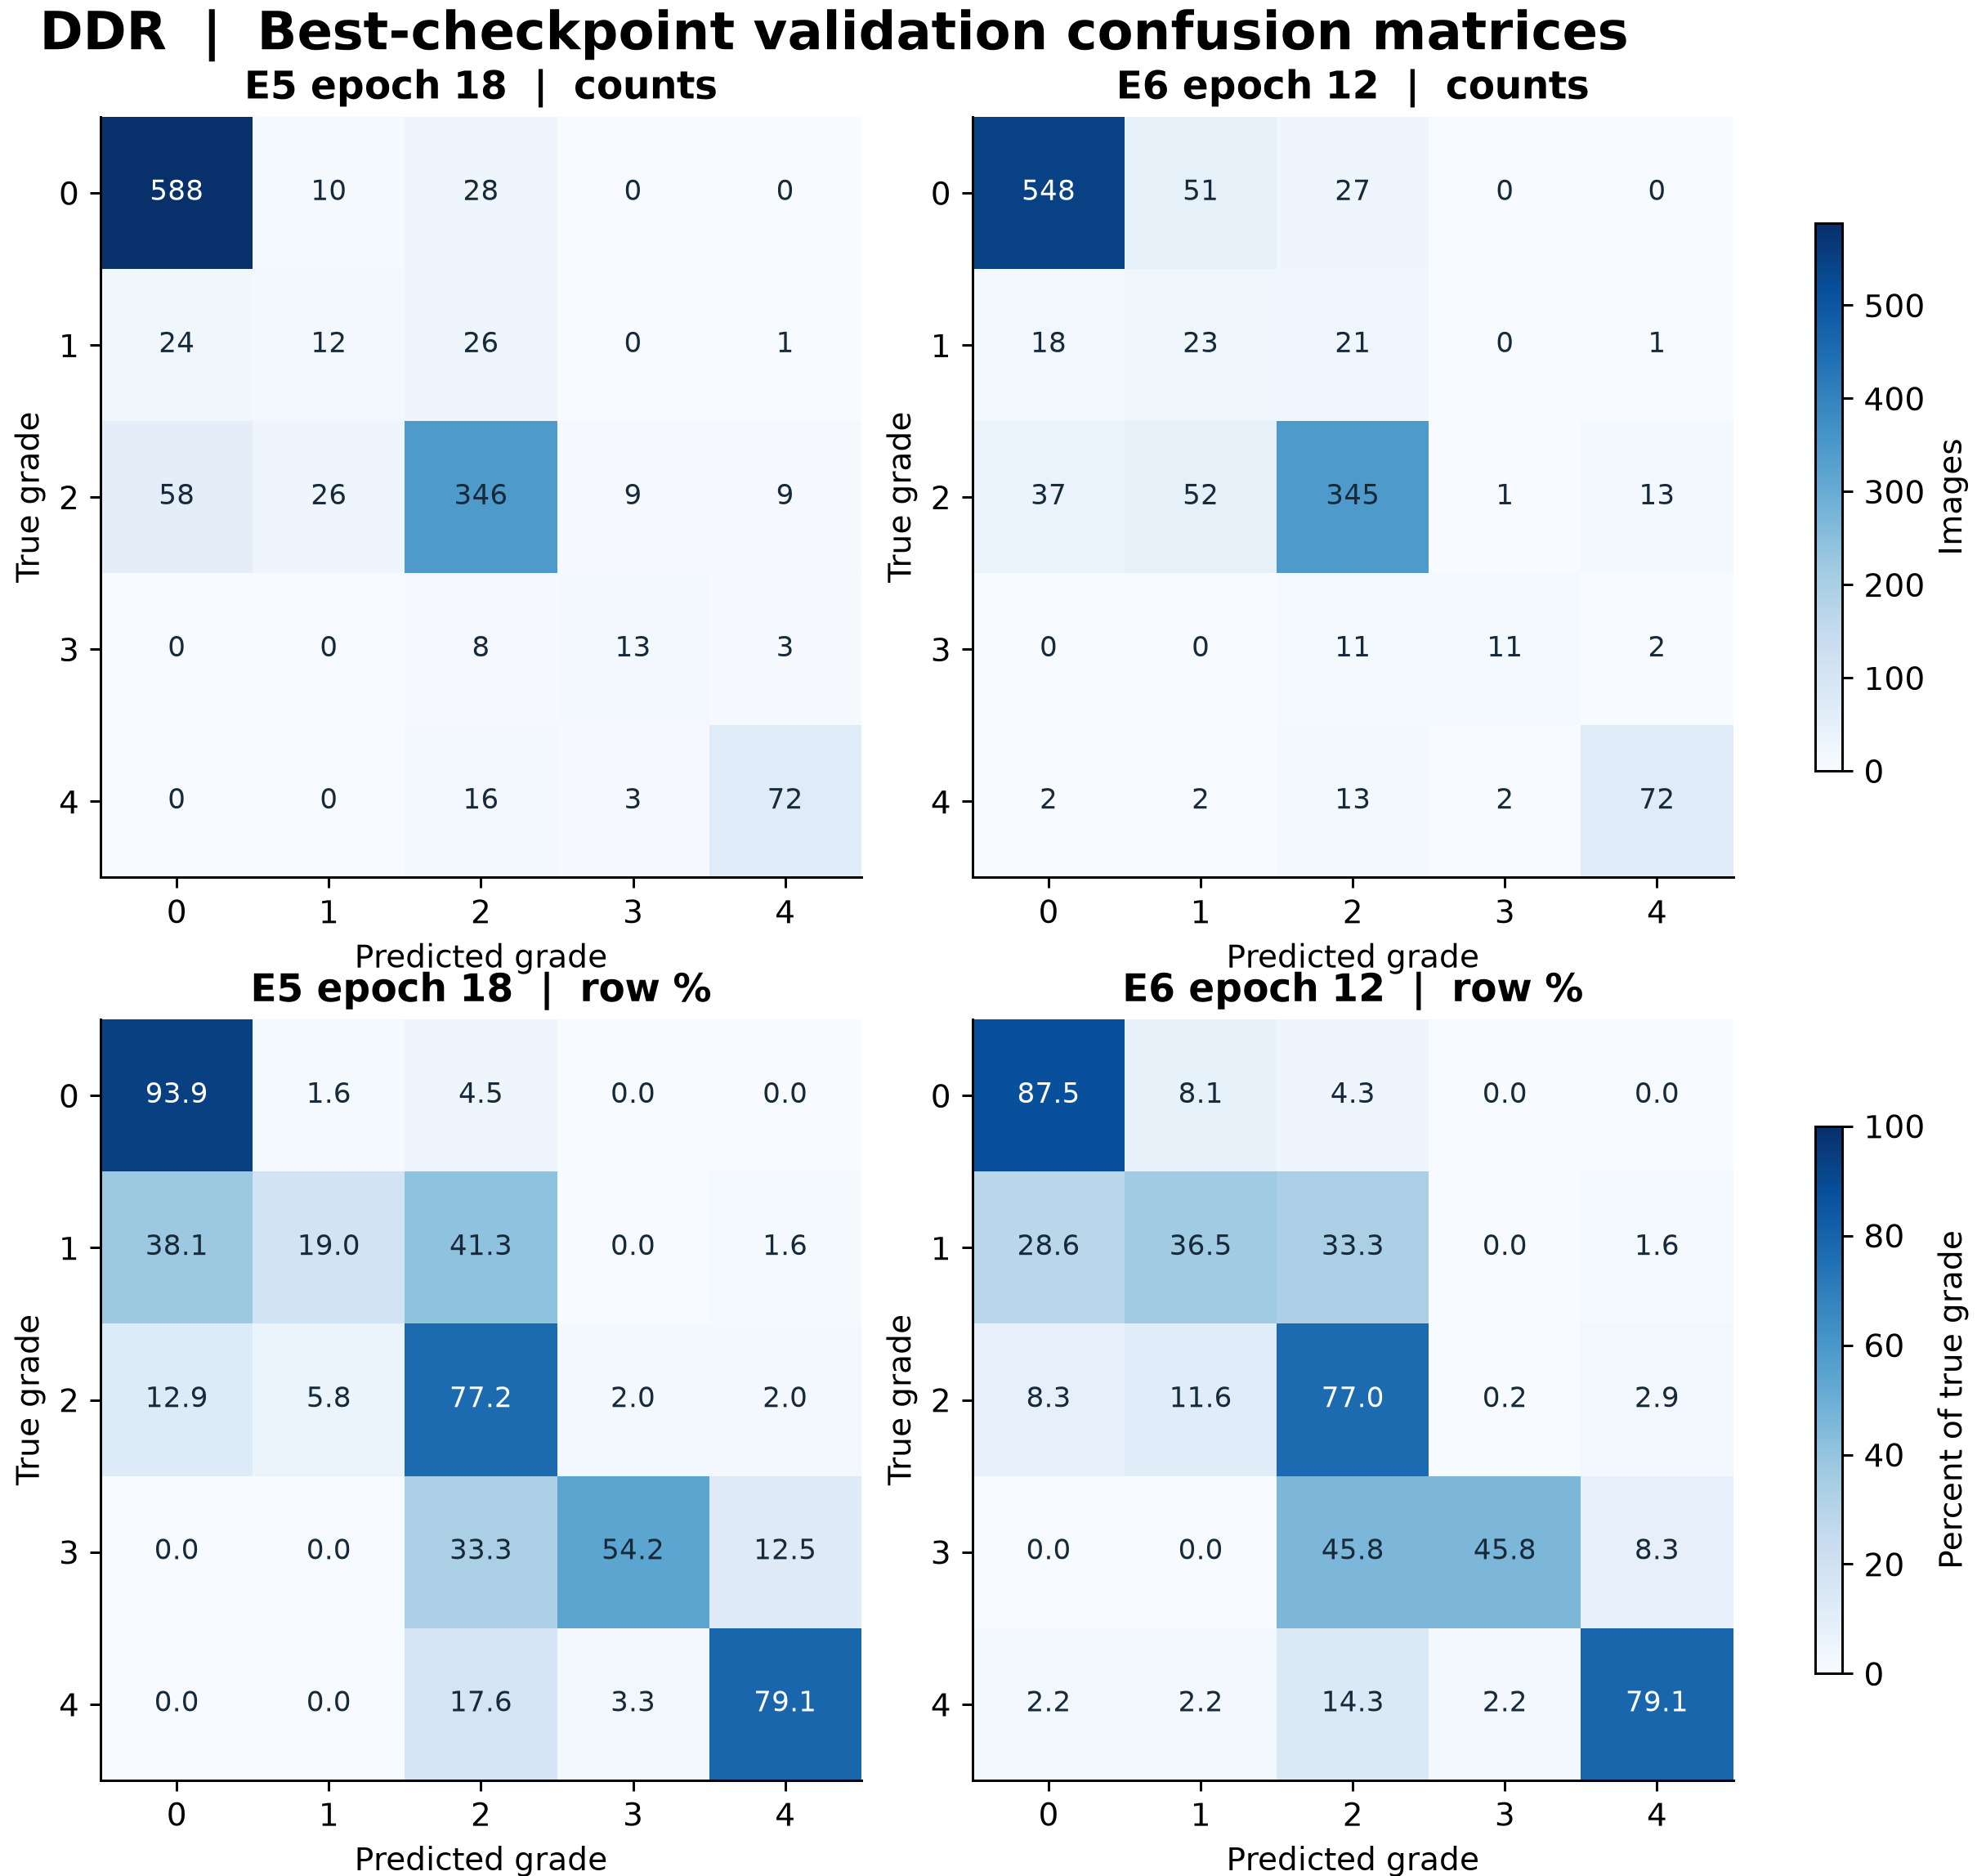

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'docs/figures/ddr_confusion.png')))

The saved score panel below places each method's selected epoch on the full recorded histories. Training and validation panels use their respective splits.

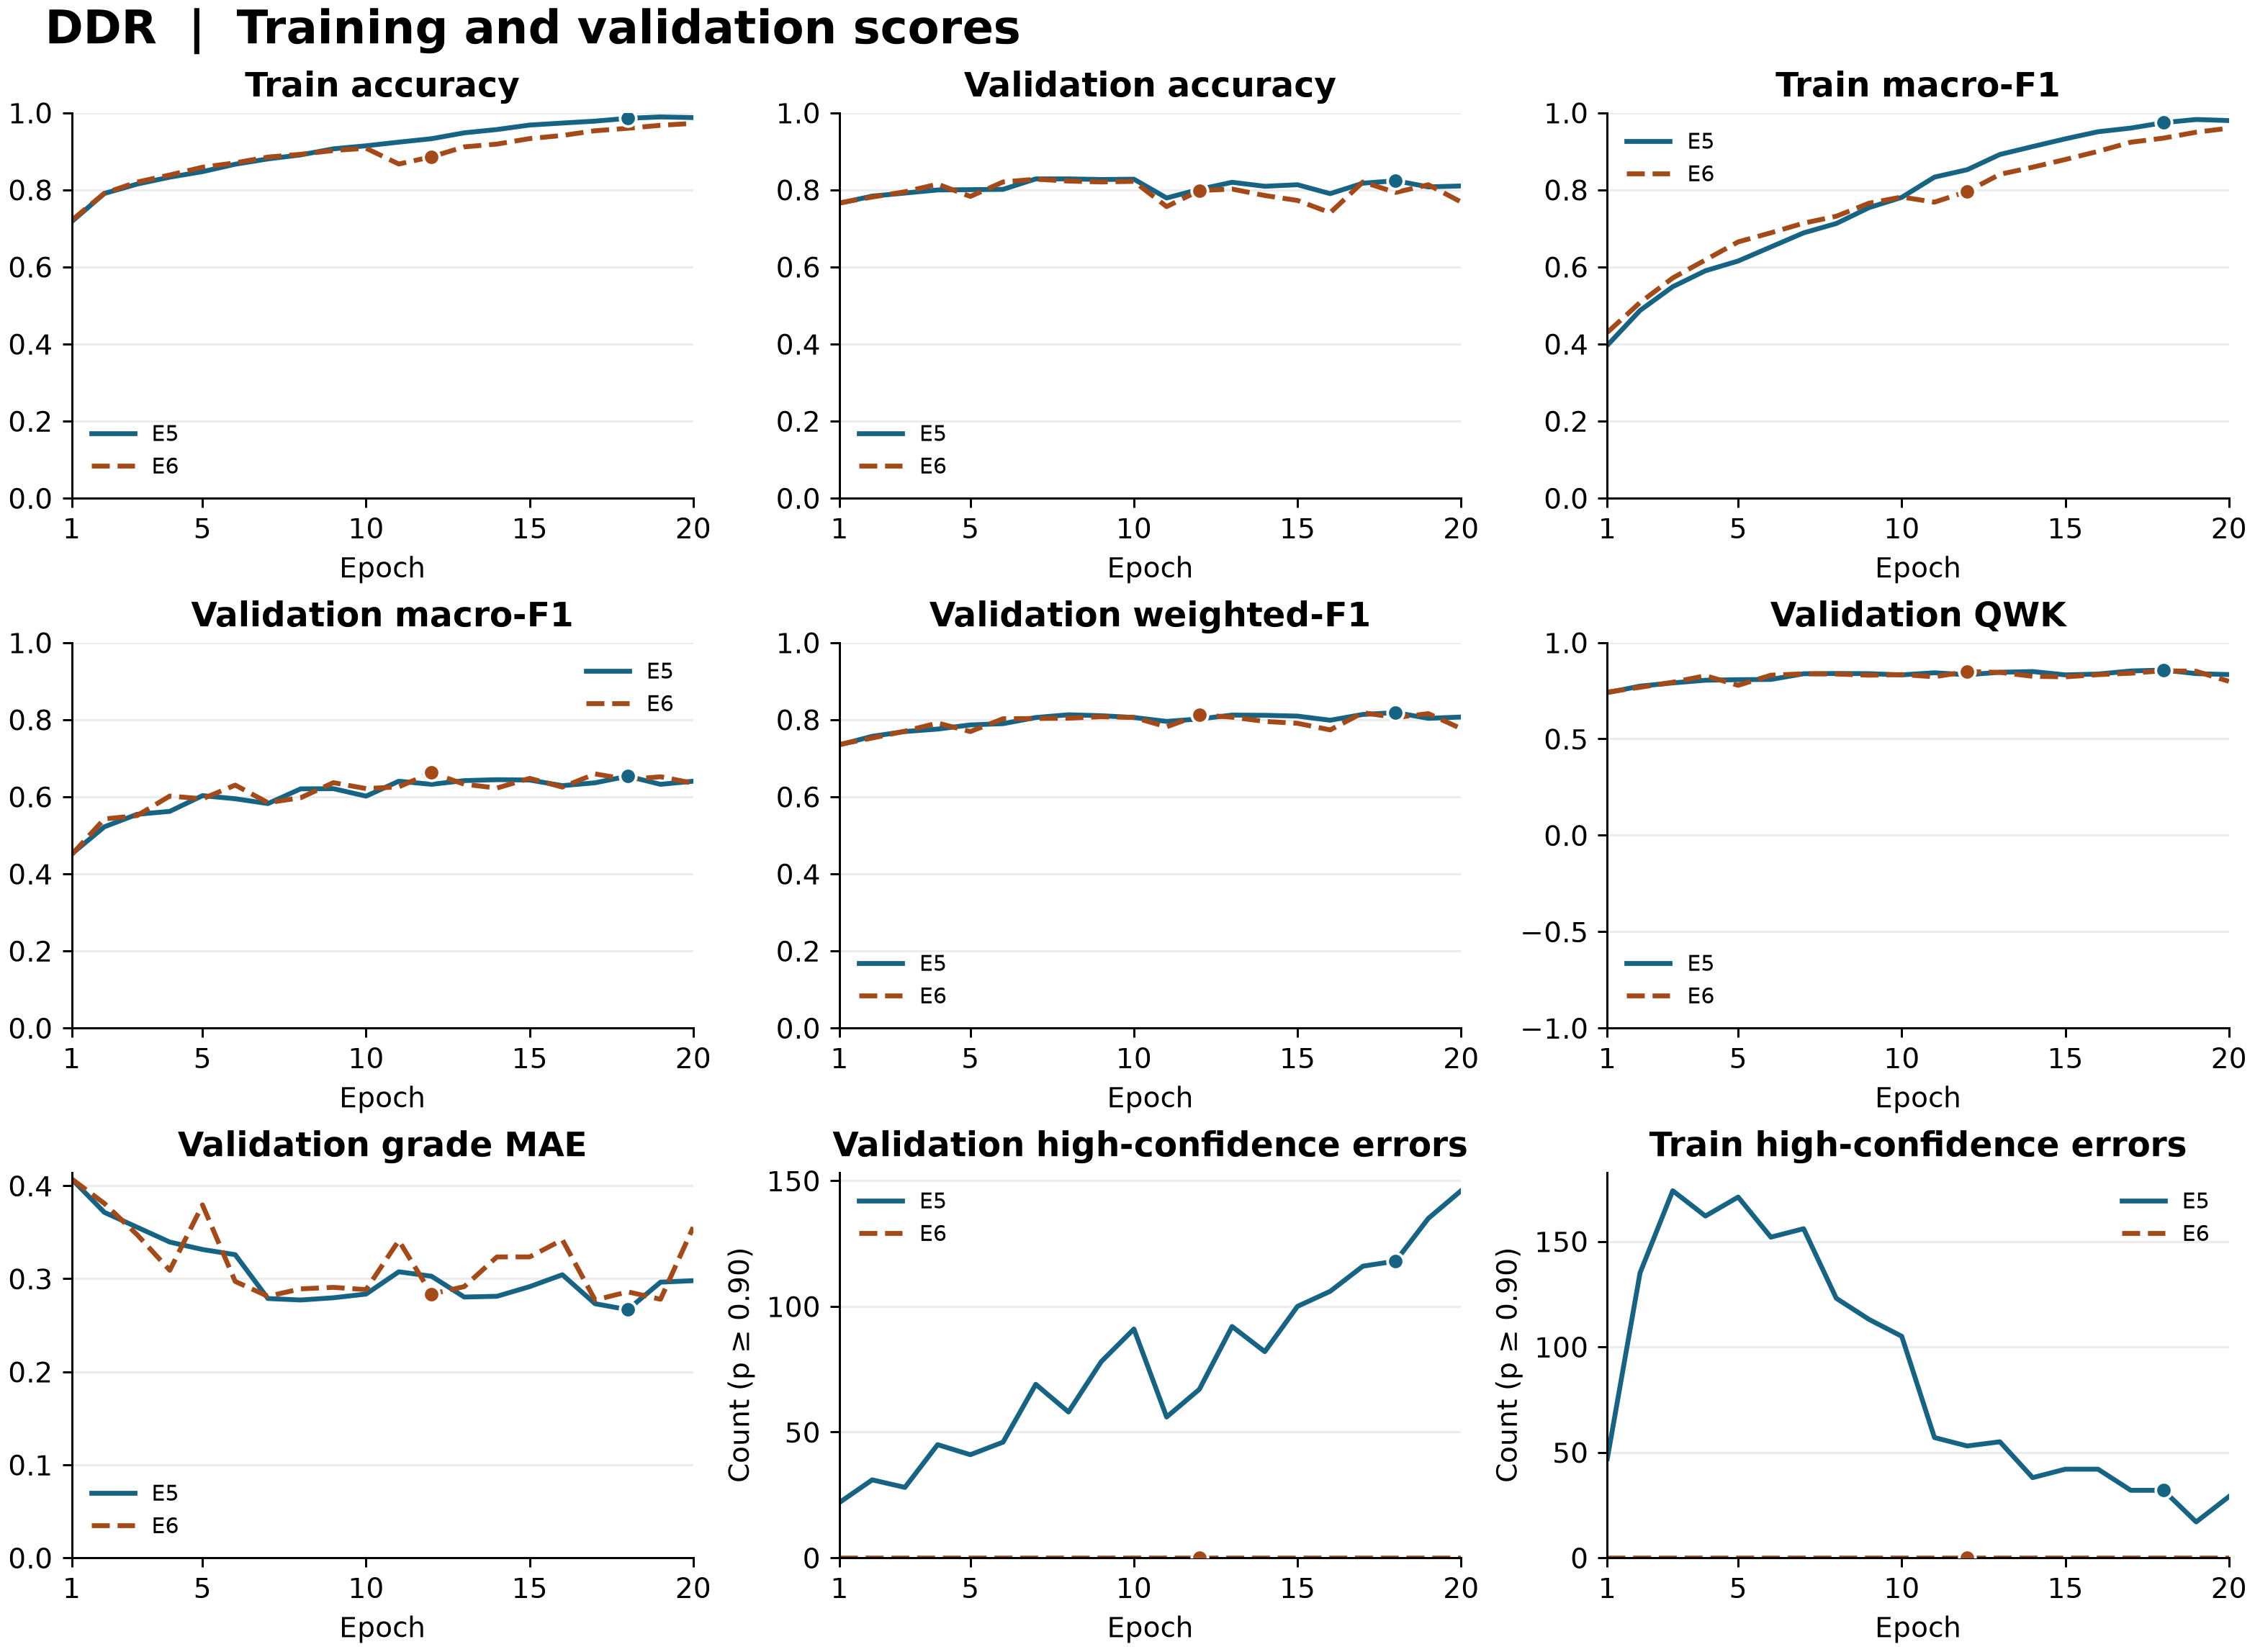

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'docs/figures/ddr_epoch_scores.png')))

## Interpretation and limits

On this dataset, E6 minus E5 is +0.009256 macro-F1, -0.025559 accuracy and -0.007609 QWK. See the comparison for grade 1 false positives, grade 3 recall and confidence-scale caveats.

Use the [E5–E6 comparison](../../docs/E5_E6_VALIDATION.md) for the dataset-specific trade-offs, including grade 1 false positives, grade 3 recall, and the confidence-scale audit. Validation selected the best epoch, so single-run differences are descriptive.

## Optional execution of the authentic workflow

Set the external `DR_ARTIFACT_ROOT`, `DR_CONVNEXT_SNAPSHOT` and for writing steps `DR_NOTEBOOK_RUN_DIR`. Use the protocol's reviewed cache roots, size budgets and paths when applicable. `DR_MANIFEST_SOURCE_ROOT` supports moved roots for E5–E7. Authorize the local snapshot explicitly via `DR_TRUST_LEGACY_BIN=1` where required. GPU actions also require `DR_GPU_ALLOCATION_CONFIRMED=1`. 

The [shared workflow bridge](../experiment_workflow.py) lists the exact environment keys and dispatches to the original CLI. Choose one step and enable its switch. Outputs must use a fresh external location. Report identity and cache validity remain enforced by the runner.

In [ ]:
from notebooks.experiment_workflow import run_step

ACTION = None
RUN_PREFLIGHT = False
RUN_CACHE = False
RUN_INPUT_VERIFICATION = False
RUN_GPU_SMOKE = False
RUN_BENCHMARK = False
RUN_TRAINING = False
RUN_CHECKPOINT_EXPORT = False
RUN_PRUNING = False
RUN_FINAL_TEST = False
if RUN_CHECKPOINT_EXPORT or RUN_PRUNING or RUN_FINAL_TEST:
    raise ValueError("Export, pruning and final-test inference are outside this workflow.")
run_step(ROOT, METHOD, DATASET, ACTION, CONFIG, {
    "preflight": RUN_PREFLIGHT, "estimate-cache": RUN_PREFLIGHT, "prepare-cache": RUN_CACHE,
    "verify-inputs": RUN_INPUT_VERIFICATION, "smoke": RUN_GPU_SMOKE,
    "benchmark": RUN_BENCHMARK, "train": RUN_TRAINING,
})